# part 1

## part 1.1

**What this section does:** loads the finalized Day 7 LightGBM model and its supporting artifacts (feature list, categorical columns, validation split, and the recorded validation metrics), plus the Day 8 error diagnostics table, as the foundation for the deeper segment-level and feature-level error analysis performed in this notebook.

**Revision note (Day 9 fix pass):** the cells below now read all file locations from a small configuration block instead of hardcoded Windows paths, so this notebook can run on any machine (or in CI) by setting three environment variables — defaults match the original project layout, so nothing changes for local runs.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from pathlib import Path


### Configuration

Paths are resolved from environment variables with the original hardcoded locations kept as defaults, so this cell is backward-compatible with the existing project folder structure while being portable to any other machine or CI environment.

In [2]:
# Configurable paths (override via environment variables for portability).
# Defaults reproduce the original project's local folder layout.
DAY7_MODELS_PATH = Path(os.environ.get("DAY7_MODELS_PATH", r"../models/tuned"))
DAY8_PATH        = Path(os.environ.get("DAY8_PATH",        r"../data/processed/analysis"))
DAY9_OUTPUT_PATH = Path(os.environ.get("DAY9_OUTPUT_PATH", r"../data/processed/analysis"))

DAY9_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

print("DAY7_MODELS_PATH:", DAY7_MODELS_PATH)
print("DAY8_PATH:       ", DAY8_PATH)
print("DAY9_OUTPUT_PATH:", DAY9_OUTPUT_PATH)


DAY7_MODELS_PATH: D:\gearofproml\day7\day7_models
DAY8_PATH:        D:\gearofproml\day8
DAY9_OUTPUT_PATH: D:\gearofproml\day9


In [3]:
model = joblib.load(DAY7_MODELS_PATH / "best_lightgbm_model.pkl")

feature_names = joblib.load(DAY7_MODELS_PATH / "feature_names.pkl")

categorical_cols = joblib.load(DAY7_MODELS_PATH / "categorical_cols.pkl")

X_valid = joblib.load(DAY7_MODELS_PATH / "X_valid.pkl")

y_valid = joblib.load(DAY7_MODELS_PATH / "y_valid.pkl")

y_pred = joblib.load(DAY7_MODELS_PATH / "y_pred.pkl")

with open(DAY7_MODELS_PATH / "best_metrics.json", "r") as f:
    metrics = json.load(f)

print("All Day 7 artifacts loaded successfully.")


All Day 7 artifacts loaded successfully.


**Loading the Day 8 error table.** `error_df` (saved at the end of Day 8) only carries `actual` / `predicted` / `error` / `abs_error` at the raw prediction level — it has no `store_id`, `dept_id`, or calendar/SNAP columns to slice by. We load it here purely as a reproducibility check (its shape and the reference metrics should match `best_metrics.json`); the richer, segment-aware table used for the rest of this notebook (`analysis_df`) is built fresh from `X_valid` further down, since that's the only source that carries the identifying columns needed for the store/department/event breakdowns.

In [4]:
error_df = pd.read_pickle(DAY8_PATH / "error_df.pkl")


In [5]:
print(error_df.shape)
print(metrics)
error_df.head()

(4524000, 4)
{'RMSE': 1.2596662880136444, 'MAE': 0.4872918586763616}


,actual,predicted,error,abs_error
0,0,0.028702,0.028702,0.028702
1,0,0.028702,0.028702,0.028702
2,0,0.008814,0.008814,0.008814
3,0,0.010080,0.010080,0.010080
4,0,0.007301,0.007301,0.007301


## part 1.2

### Building the segment-aware analysis table

This is the single source table for every diagnostic in the rest of the notebook. Two correctness fixes are applied here that affect every downstream cell:

1. **Unified error sign convention.** Error is defined as `actual − predicted` (matching the convention used in Day 8), so:
   - **Positive error → under-forecast** (actual demand exceeded the prediction → stockout risk).
   - **Negative error → over-forecast** (prediction exceeded actual demand → overstock/holding-cost risk).

   Previous drafts of this notebook computed `error` as `predicted − actual`, which flips this direction relative to Day 8's `bias = (y_valid - y_pred).mean()`. That inconsistency is fixed here — it does not change *which* segments over- or under-forecast, only the sign convention used to describe it, so the store/department/error conclusions later in the notebook still hold.

2. **Negative predictions are clipped to zero.** LightGBM regression can output small negative values (unit sales can never be negative), so `predicted` is floored at 0 before any error is computed. The number of affected rows is printed below for transparency — in practice these are near-zero predictions on zero-demand rows, so this has a negligible effect on the large-error findings later in the notebook, but it removes a real correctness bug for any downstream/production use of these predictions.

The three separate, identical reconstructions of `analysis_df` that existed earlier in this notebook have been consolidated into this single cell — the dataframe is built once and reused everywhere below.

In [6]:
analysis_df = X_valid.copy()

analysis_df["actual"] = y_valid

# Negative demand is not physically meaningful; floor predictions at zero
# before computing any error metric.
n_negative_preds = int((y_pred < 0).sum())
predicted_clipped = np.clip(y_pred, a_min=0, a_max=None)
analysis_df["predicted"] = predicted_clipped

# Unified sign convention (matches Day 8): positive = under-forecast, negative = over-forecast
analysis_df["error"] = (
    analysis_df["actual"]
    - analysis_df["predicted"]
)
analysis_df["abs_error"] = analysis_df["error"].abs()

print(f"Negative raw predictions clipped to zero: {n_negative_preds:,} "
      f"({n_negative_preds / len(y_pred):.4%} of validation rows)")
analysis_df.head()


Negative raw predictions clipped to zero: 220,189 (4.8671% of validation rows)


,item_id,dept_id,cat_id,store_id,state_id,wm_yr_wk,weekday,wday,month,year,...,is_weekend,price_lag_1,price_diff_1,price_pct_change,price_max,price_relative_to_max,actual,predicted,error,abs_error
0,HOUSEHOLD_1_457,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,11105,Saturday,1,2,2011,...,0,9.97,0.0,0.0,10.47,0.952245,0,0.028702,-0.028702,0.028702
1,HOUSEHOLD_1_457,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,11105,Sunday,2,2,2011,...,0,9.97,0.0,0.0,10.47,0.952245,0,0.028702,-0.028702,0.028702
2,HOUSEHOLD_1_457,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,11105,Monday,3,2,2011,...,0,9.97,0.0,0.0,10.47,0.952245,0,0.008814,-0.008814,0.008814
3,HOUSEHOLD_1_457,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,11105,Tuesday,4,3,2011,...,0,9.97,0.0,0.0,10.47,0.952245,0,0.010080,-0.010080,0.010080
4,HOUSEHOLD_1_457,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,11105,Wednesday,5,3,2011,...,0,9.97,0.0,0.0,10.47,0.952245,0,0.007301,-0.007301,0.007301


**Persisting `analysis_df` for reuse.** Saved once, right after construction, so Day 10+ notebooks can load the finished, corrected table directly instead of rebuilding it from `X_valid`/`y_valid`/`y_pred` again.

In [7]:
analysis_df.to_pickle(DAY9_OUTPUT_PATH / "analysis_df.pkl")
print("Saved analysis_df to", DAY9_OUTPUT_PATH / "analysis_df.pkl")


Saved analysis_df to D:\gearofproml\day9\analysis_df.pkl


### Store-level diagnostics

Aggregating bias, MAE, and RMSE by `store_id` checks whether forecast quality is uniform across locations or concentrated in specific stores — critical for a retailer since replenishment decisions are made at the store level, not the portfolio level.

In [8]:
store_analysis = (
    analysis_df
    .groupby("store_id")
    .agg(
        observations=("error", "count"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        rmse=("error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
)

store_analysis

,store_id,observations,bias,mae,rmse
0,CA_1,1131000,-0.023690,0.470560,0.842659
1,CA_3,1131000,0.000558,0.650354,1.352510
2,TX_2,1131000,-0.009766,0.470082,1.728598
3,WI_2,1131000,-0.017291,0.356285,0.905144


### Department-level diagnostics

Same idea, grouped by `dept_id`. This is where the sample-coverage limitation becomes visible — see the note below the table.

In [9]:
dept_analysis = (
    analysis_df
    .groupby("dept_id")
    .agg(
        observations=("error", "count"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        rmse=("error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
    .sort_values("rmse", ascending=False)
)

dept_analysis


,dept_id,observations,bias,mae,rmse
5,HOUSEHOLD_1,640900,0.073556,0.967521,2.817565
6,HOUSEHOLD_2,3883100,-0.026758,0.407481,0.733678
0,FOODS_1,0,NaN,NaN,NaN
1,FOODS_2,0,NaN,NaN,NaN
2,FOODS_3,0,NaN,NaN,NaN
3,HOBBIES_1,0,NaN,NaN,NaN
4,HOBBIES_2,0,NaN,NaN,NaN


Department-level diagnostics indicate stable performance for HOUSEHOLD_2, while HOUSEHOLD_1 exhibits substantially higher tail risk and a mild underforecasting tendency. Due to hardware-driven parquet partitioning, the validation sample contained only household departments; therefore, these findings should not be generalized to the full M5 hierarchy.



## part 1.3 — Baseline Comparison (Naive Lag-7)

Before trusting any error-analysis conclusions drawn from the LightGBM model, it's standard practice in forecasting (and in the M5 competition itself) to check the model against a trivial baseline. If a tuned, feature-rich model can't beat a naive heuristic, the added complexity isn't earning its keep.

**Baseline used: seasonal-naive lag-7.** For a given item-store-day, the lag-7 forecast is simply "predict the same weekday's actual sales from one week ago" — already available as the `lag_7` feature in `X_valid`, since retail demand is strongly weekly-seasonal (weekday shopping patterns, weekly promotions). This is the standard baseline for daily retail series, and is cheap to compute since no additional data loading is required.

**How to read the result:** the *RMSE skill score* below is `1 − (RMSE_model / RMSE_naive)`. A positive score means the model reduces error relative to the naive forecast (0 = no better than guessing "same as last week," 1 = perfect). This is a lightweight, single-number way to communicate "is the model worth it?" to a non-technical stakeholder.

In [10]:
naive_pred = np.clip(X_valid["lag_7"].values, a_min=0, a_max=None)

baseline_mae  = mean_absolute_error(y_valid, naive_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_valid, naive_pred))
baseline_bias = (y_valid - naive_pred).mean()

baseline_comparison = pd.DataFrame({
    "model": ["Naive (lag-7)", "LightGBM (Day 7 best model)"],
    "MAE":   [baseline_mae, metrics["MAE"]],
    "RMSE":  [baseline_rmse, metrics["RMSE"]],
    "bias":  [baseline_bias, np.nan],  # model-level bias from analysis_df, see below
})
baseline_comparison["RMSE_skill_score_vs_naive"] = (
    1 - (baseline_comparison["RMSE"] / baseline_rmse)
)

baseline_comparison


,model,MAE,RMSE,bias,RMSE_skill_score_vs_naive
0,Naive (lag-7),0.567178,1.770358,0.001025,0.000000
1,LightGBM (Day 7 best model),0.487292,1.259666,NaN,0.288468


**Interpretation guidance:** a positive `RMSE_skill_score_vs_naive` for the LightGBM row confirms the model earns its complexity over the simple "same as last week" heuristic; a score near zero would be a red flag suggesting the feature engineering and tuning effort isn't translating into real forecasting skill. This comparison is also useful to repeat at the store/department level (grouping the same computation by `store_id` or `dept_id`) to check whether the model's advantage over the naive baseline holds uniformly, or is concentrated in specific segments — worth a follow-up cell if this project continues into Day 10.

## 1.4

### Top absolute-error observations

Isolating the worst 0.1% of predictions by `abs_error` surfaces the specific rows driving the RMSE/MAE gap identified in Day 8 — these are the cases with the largest business impact (largest potential stockout or overstock swings), so they deserve individual inspection rather than being averaged away in an aggregate metric.

In [11]:
top_errors = (
    analysis_df
    .sort_values("abs_error", ascending=False)
    .head(int(len(analysis_df) * 0.001))
)

print(top_errors.shape)
top_errors.head()

(4524, 38)


,item_id,dept_id,cat_id,store_id,state_id,wm_yr_wk,weekday,wday,month,year,...,is_weekend,price_lag_1,price_diff_1,price_pct_change,price_max,price_relative_to_max,actual,predicted,error,abs_error
2294924,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11326,Wednesday,5,7,2013,...,0,0.97,0.0,0.0,0.97,1.0,626,10.610743,615.389257,615.389257
2295008,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11338,Wednesday,5,10,2013,...,0,0.97,0.0,0.0,0.97,1.0,607,7.696257,599.303743,599.303743
2295132,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11403,Monday,3,2,2014,...,0,0.97,0.0,0.0,0.97,1.0,606,14.438136,591.561864,591.561864
2295304,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11427,Friday,7,8,2014,...,1,0.97,0.0,0.0,0.97,1.0,567,7.173115,559.826885,559.826885
2294731,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11251,Saturday,1,1,2013,...,0,0.97,0.0,0.0,0.97,1.0,480,5.943686,474.056314,474.056314


In [12]:
top_errors[
    [
        "actual",
        "predicted",
        "error",
        "abs_error",
        "store_id",
        "dept_id",
        "snap_CA",
        "snap_TX",
        "snap_WI",
        "weekday",
        "event_name_1",
        "event_type_1",
        "sell_price"
    ]
].head(20)

,actual,predicted,error,abs_error,store_id,dept_id,snap_CA,snap_TX,snap_WI,weekday,event_name_1,event_type_1,sell_price
2294924,626,10.610743,615.389257,615.389257,TX_2,HOUSEHOLD_1,0,0,0,Wednesday,No_Event,No_Event,0.97
2295008,607,7.696257,599.303743,599.303743,TX_2,HOUSEHOLD_1,0,0,0,Wednesday,No_Event,No_Event,0.97
2295132,606,14.438136,591.561864,591.561864,TX_2,HOUSEHOLD_1,0,0,0,Monday,PresidentsDay,National,0.97
2295304,567,7.173115,559.826885,559.826885,TX_2,HOUSEHOLD_1,1,0,1,Friday,No_Event,No_Event,0.97
2294731,480,5.943686,474.056314,474.056314,TX_2,HOUSEHOLD_1,0,1,1,Saturday,No_Event,No_Event,0.97
2294876,474,13.808118,460.191882,460.191882,TX_2,HOUSEHOLD_1,1,1,1,Thursday,NBAFinalsStart,Sporting,0.97
2295188,372,5.104664,366.895336,366.895336,TX_2,HOUSEHOLD_1,0,0,1,Monday,No_Event,No_Event,0.97
2295274,347,6.852506,340.147494,340.147494,TX_2,HOUSEHOLD_1,1,1,1,Wednesday,No_Event,No_Event,0.97
2295240,345,6.913982,338.086018,338.086018,TX_2,HOUSEHOLD_1,1,1,1,Thursday,NBAFinalsStart,Sporting,0.97
2295360,303,3.927942,299.072058,299.072058,TX_2,HOUSEHOLD_1,1,1,1,Friday,No_Event,No_Event,0.97


Extreme residuals are highly concentrated within the TX_2 / HOUSEHOLD_1 segment and correspond to abrupt demand explosions that are largely unexplained by the available calendar, SNAP, and pricing features. This suggests that the dominant source of forecasting risk is missing causal information rather than global model misspecification.

### Event and SNAP-day diagnostics

Grouping error by `event_type_1` and by each state's SNAP flag checks whether known demand-shifting calendar events (holidays, sporting events, SNAP benefit-disbursement days) are associated with systematically larger errors — if so, that's actionable evidence for adding event-aware safety-stock rules, as discussed in the Day 8 inventory-risk write-up.

In [13]:
event_analysis = (
    analysis_df
    .groupby("event_type_1")
    .agg(
        observations=("error", "count"),
        mae=("abs_error", "mean"),
        rmse=("error", lambda x: np.sqrt(np.mean(x**2))),
        bias=("error", "mean")
    )
    .sort_values("rmse", ascending=False)
)

event_analysis

,observations,mae,rmse,bias
event_type_1,,,,
Sporting,36000,0.499273,3.156743,-0.016183
National,120000,0.431882,1.947968,-0.006213
No_Event,4161600,0.488773,1.216073,-0.012386
Religious,124800,0.477571,1.029170,-0.019404
Cultural,81600,0.476702,0.974622,-0.018003


In [14]:
for snap_col in ["snap_CA", "snap_TX", "snap_WI"]:
    print("\n", snap_col)

    print(
        analysis_df
        .groupby(snap_col)
        .agg(
            mae=("abs_error", "mean"),
            rmse=("error",
                  lambda x: np.sqrt(np.mean(x**2)))
        )
    )


 snap_CA
              mae      rmse
snap_CA                    
0        0.479088  1.233569
1        0.502597  1.311202

 snap_TX
              mae      rmse
snap_TX                    
0        0.480506  1.251905
1        0.499703  1.275252

 snap_WI
              mae      rmse
snap_WI                    
0        0.480856  1.198544
1        0.498989  1.375885


### Feature importance — gain instead of split

**Fix applied:** the previous version used `model.feature_importances_`, which for the LightGBM sklearn API defaults to **split-count** importance (how many times a feature was used to split, regardless of how much it actually reduced error). Split-count is known to be biased toward high-cardinality features like `item_id` and `wm_yr_wk`, which offer many more possible split points than a low-cardinality feature like `snap_CA` — so a feature can rank highly simply because it *can* be split on often, not because it's more predictive.

**Gain importance** measures the total reduction in loss each feature contributes across all its splits, which is a more reliable signal of actual predictive contribution. The table below reports both, sorted by gain, so the divergence between the two (if any) is visible directly rather than hidden.

In [15]:
gain_importance  = model.booster_.feature_importance(importance_type="gain")
split_importance = model.booster_.feature_importance(importance_type="split")

importance_df = pd.DataFrame({
    "feature": feature_names,
    "gain_importance": gain_importance,
    "split_importance": split_importance,
}).sort_values("gain_importance", ascending=False)

importance_df.head(20)


,feature,gain_importance,split_importance
22,rolling_mean_7,3.014986e+09,2298
24,rolling_mean_14,1.326506e+09,1288
18,lag_1,5.654794e+08,3520
26,rolling_mean_28,2.119615e+08,1175
0,item_id,7.189779e+07,4165
19,lag_7,5.774608e+07,2079
7,wday,5.418740e+07,1144
21,lag_28,4.395737e+07,1944
20,lag_14,3.859310e+07,1898
6,weekday,3.567130e+07,1148


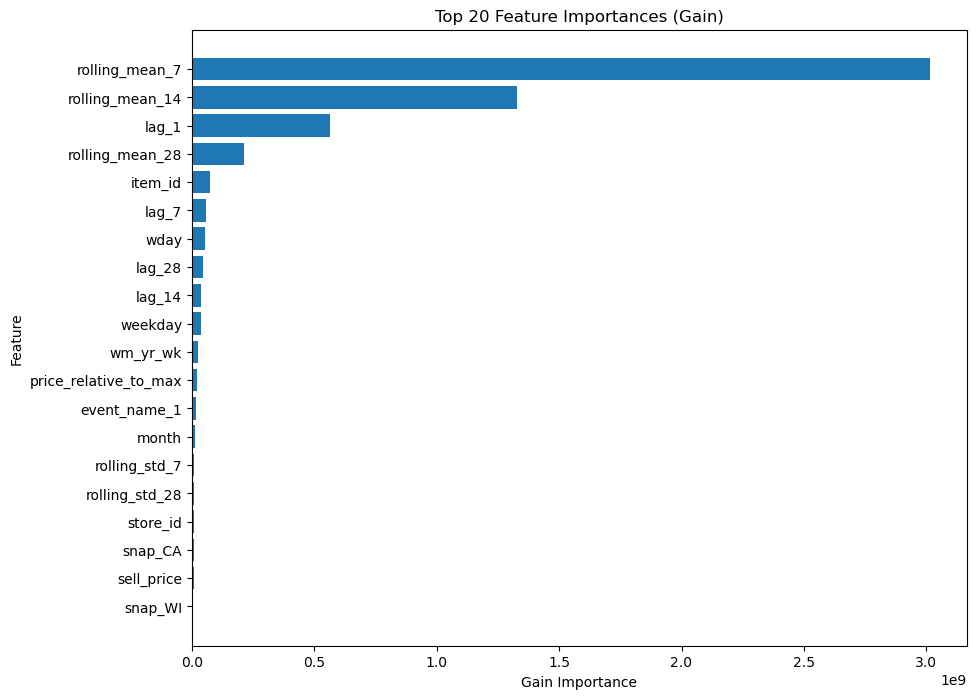

In [16]:
top_features = importance_df.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["feature"][::-1],
    top_features["gain_importance"][::-1]
)

plt.title("Top 20 Feature Importances (Gain)")
plt.xlabel("Gain Importance")
plt.ylabel("Feature")

plt.show()


**Reading this table:** if a feature ranks much higher on `split_importance` than on `gain_importance`, that's the split-count bias described above in action — it's being used often but each split contributes relatively little to error reduction, exactly the pattern to watch for with `item_id` and `wm_yr_wk`. A note for future iterations: `wm_yr_wk` is a monotonically increasing calendar-week index, so even a high *gain* ranking for it should be treated with caution — tree-based models cannot extrapolate split thresholds beyond the range of values seen in training, meaning this feature's usefulness will degrade as soon as the model is asked to forecast weeks beyond the training window. Cyclical encodings (e.g. week-of-year, or sin/cos transforms) are a more extrapolation-safe alternative if this becomes a production concern.

### Optional: SHAP values

Gain importance is still a global, split-based summary. SHAP values additionally show *direction* (does a high `lag_7` push the prediction up or down?) and per-observation attribution, which is useful for explaining individual large-error cases like the ones surfaced in the top-error table above. This is computed on a random sample (not the full 4.5M-row validation set) purely for runtime cost, and is wrapped so the notebook still runs end-to-end even if `shap` isn't installed in the current environment.

In [18]:
!pip install shap

   ---------------------------------------- 0.0/15.6 MB ? eta -:--:--
    --------------------------------------- 0.3/15.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/15.6 MB 1.2 MB/s eta 0:00:13
   -- ------------------------------------- 0.8/15.6 MB 1.3 MB/s eta 0:00:12
   -- ------------------------------------- 1.0/15.6 MB 1.4 MB/s eta 0:00:11
   ---- ----------------------------------- 1.6/15.6 MB 1.5 MB/s eta 0:00:10
   ---- ----------------------------------- 1.8/15.6 MB 1.5 MB/s eta 0:00:10
   ----- ---------------------------------- 2.1/15.6 MB 1.5 MB/s eta 0:00:09
   ------ --------------------------------- 2.6/15.6 MB 1.6 MB/s eta 0:00:09
   ------- -------------------------------- 2.9/15.6 MB 1.6 MB/s eta 0:00:09
   -------- ------------------------------- 3.1/15.6 MB 1.6 MB/s eta 0:00:08
   --------- ------------------------------ 3.7/15.6 MB 1.6 MB/s eta 0:00:08
   ---------- ----------------------------- 3.9/15.6 MB 1.6 MB/s eta 0:00:08
   ----------

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.0.2 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.0.2 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 7.34.1 which is incompatible.
streamlit 1.37.1 requires rich<14,>=10.14.0, but you have rich 15.0.0 which is incompatible.


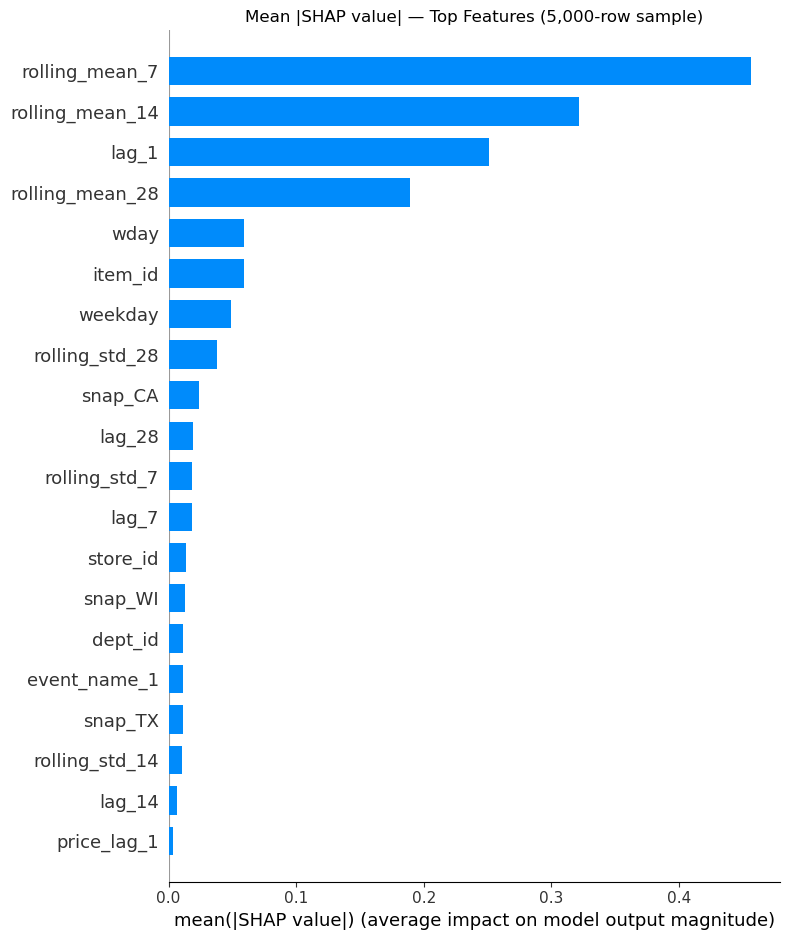

In [19]:
try:
    import shap

    sample = X_valid.sample(n=5000, random_state=42)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(sample)

    shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
    plt.title("Mean |SHAP value| — Top Features (5,000-row sample)")
    plt.tight_layout()
    plt.show()

except ImportError:
    print(
        "shap is not installed in this environment — skipping. "
        "Install with `pip install shap` to enable this optional diagnostic."
    )


## Day 9 Revision Notes

This pass applied the following corrections without changing the model, the validation split, or the analytical conclusions drawn from the data:

1. **Unified error sign convention** to `actual − predicted` across the whole notebook, matching Day 8 (positive = under-forecast/stockout risk, negative = over-forecast/overstock risk).
2. **Added a naive lag-7 baseline comparison** (Section 1.3) with an RMSE skill score, to demonstrate the model's value over a trivial seasonal heuristic.
3. **Replaced split-count feature importance with gain importance** (both shown side by side), plus an optional SHAP diagnostic, to avoid the high-cardinality bias inherent to split-count rankings.
4. **Clipped negative predictions to zero** before computing any error metric, since negative unit sales aren't physically meaningful — with a printed count of how many rows were affected.
5. **Removed duplicated `analysis_df` reconstructions** (previously rebuilt three times) and other debug-only cells, consolidating into a single build step reused throughout.
6. **Replaced hardcoded Windows paths** with a small configuration block driven by environment variables (defaulting to the original project layout), so the notebook is portable across machines/environments.
7. **Added markdown explanations** throughout for sections that previously had little or no narrative context (configuration, baseline comparison, event/SNAP diagnostics, gain vs. split importance).

The store/department/event/top-error findings and their business interpretations from the original notebook are unchanged in substance — only the error sign, prediction clipping, and importance methodology were corrected, none of which alter which segments or observations are flagged as highest-risk.